In [2]:
 # Cell 1: Imports and Configuration

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report
import json
import os

# --- Configuration ---
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 32
NUM_EPOCHS = 5
LEARNING_RATE = 0.001
NUM_CLASSES = 7
print(f"Using device: {DEVICE}")


Using device: cpu


In [3]:
# ============================================================
# CELL 2: Load CSVs, take a stratified subset, build Dataset/DataLoader
# Subset = 500 per class × 7 = ~3,500 images → epoch ~5 min on CPU
# ============================================================
train_df = pd.read_csv('train.csv')
val_df   = pd.read_csv('val.csv')

train_df = train_df.groupby('label', group_keys=False).apply(
    lambda x: x.sample(n=min(500, len(x)), random_state=42)
).reset_index(drop=True)
print(f"Using {len(train_df)} training images")

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class ClassroomDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform
        self.label_map = {label: idx for idx, label in enumerate(sorted(dataframe['label'].unique()))}
    def __len__(self): return len(self.dataframe)
    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        image = Image.open(row['image_path']).convert('RGB')
        label = self.label_map[row['label']]
        if self.transform: image = self.transform(image)
        return image, label

train_dataset = ClassroomDataset(train_df, transform=train_transforms)
val_dataset   = ClassroomDataset(val_df, transform=val_transforms)

# num_workers=0 — Windows spawn with workers can hang Jupyter
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Batches: train={len(train_loader)}, val={len(val_loader)}")

Using 3500 training images
Batches: train=110, val=527


C:\Users\MASTER\AppData\Local\Temp\ipykernel_17808\4099833216.py:8: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  train_df = train_df.groupby('label', group_keys=False).apply(


In [4]:
# Cell 3

# Model, Loss, and Optimizer Setup


# Load pretrained ResNet-18 and replace the final fully connected layer
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, NUM_CLASSES) # Replace fc layer for 7 classes[reference:1]
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [5]:
# ============================================================
# CELL 4: Simple training loop with plain prints (no tqdm).
# Prints every 20 batches so you can see real progress.
# Expected: ~5 min per epoch on 3,500 images.
# ============================================================
import time

train_losses, val_losses = [], []
train_accs,   val_accs   = [], []

print(f"Starting: {NUM_EPOCHS} epoch(s), {len(train_loader)} batches/epoch")

for epoch in range(NUM_EPOCHS):
    epoch_start = time.time()

    # ---------- TRAIN ----------
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for step, (images, labels) in enumerate(train_loader):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0); correct += predicted.eq(labels).sum().item()

        # --- Print every 20 batches so you SEE progress ---
        if (step + 1) % 20 == 0:
            print(f"  [Epoch {epoch+1}] batch {step+1}/{len(train_loader)} | "
                  f"loss={loss.item():.4f} | acc={100*correct/total:.2f}% | "
                  f"{(time.time()-epoch_start)/60:.1f} min elapsed")

    train_loss = running_loss / len(train_loader)
    train_acc  = correct / total
    train_losses.append(train_loss); train_accs.append(train_acc)

    # ---------- VALIDATE ----------
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0); correct += predicted.eq(labels).sum().item()

    val_loss = running_loss / len(val_loader)
    val_acc  = correct / total
    val_losses.append(val_loss); val_accs.append(val_acc)

    print(f"✅ Epoch {epoch+1}/{NUM_EPOCHS} done in {(time.time()-epoch_start)/60:.1f} min | "
          f"Train Loss={train_loss:.4f} Acc={100*train_acc:.2f}% | "
          f"Val Loss={val_loss:.4f} Acc={100*val_acc:.2f}%")

Starting: 5 epoch(s), 110 batches/epoch
  [Epoch 1] batch 20/110 | loss=0.8615 | acc=49.06% | 2.3 min elapsed
  [Epoch 1] batch 40/110 | loss=1.2109 | acc=55.62% | 5.0 min elapsed
  [Epoch 1] batch 60/110 | loss=0.5806 | acc=60.16% | 8.2 min elapsed
  [Epoch 1] batch 80/110 | loss=0.7048 | acc=62.54% | 12.0 min elapsed
  [Epoch 1] batch 100/110 | loss=0.9884 | acc=65.09% | 16.5 min elapsed
✅ Epoch 1/5 done in 841.8 min | Train Loss=0.9691 Acc=65.40% | Val Loss=1.0555 Acc=58.48%
  [Epoch 2] batch 20/110 | loss=0.6571 | acc=76.09% | 2.0 min elapsed
  [Epoch 2] batch 40/110 | loss=0.3980 | acc=77.58% | 3.8 min elapsed
  [Epoch 2] batch 60/110 | loss=0.5575 | acc=77.60% | 5.7 min elapsed
  [Epoch 2] batch 80/110 | loss=0.3331 | acc=78.09% | 7.4 min elapsed
  [Epoch 2] batch 100/110 | loss=0.7301 | acc=78.38% | 9.2 min elapsed
✅ Epoch 2/5 done in 26.8 min | Train Loss=0.6023 Acc=78.51% | Val Loss=0.7446 Acc=73.07%
  [Epoch 3] batch 20/110 | loss=0.3764 | acc=83.28% | 1.8 min elapsed
  [Epoc

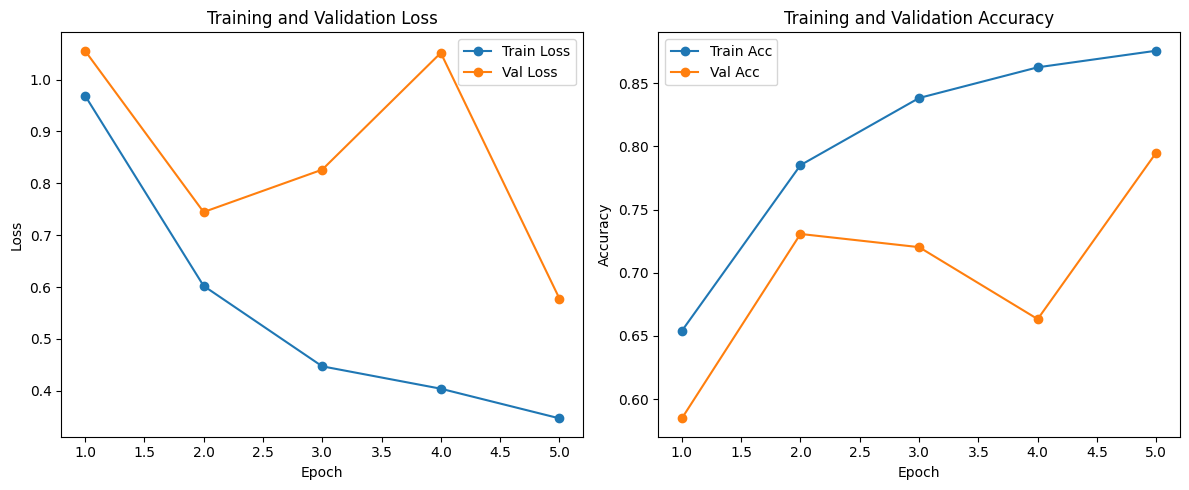

Saved training_curves.png


In [6]:
# Save training and validation loss curves as images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, NUM_EPOCHS+1), train_losses, label='Train Loss', marker='o')
plt.plot(range(1, NUM_EPOCHS+1), val_losses, label='Val Loss', marker='o')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Training and Validation Loss'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, NUM_EPOCHS+1), train_accs, label='Train Acc', marker='o')
plt.plot(range(1, NUM_EPOCHS+1), val_accs, label='Val Acc', marker='o')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('Training and Validation Accuracy'); plt.legend()

plt.tight_layout()
plt.savefig('training_curves.png') # Saves the image file
plt.show()
print("Saved training_curves.png")

## Duplicate Path Check


In [9]:
# --- Duplicate-Path Detection Routine ---
def check_duplicate_paths(train_csv_path, val_csv_path):
    """Checks for overlapping file paths between train and validation sets."""
    train_paths = set(pd.read_csv(train_csv_path)['image_path'])
    val_paths = set(pd.read_csv(val_csv_path)['image_path'])
    overlap = train_paths.intersection(val_paths)
    
    print(f"Train unique paths: {len(train_paths)}")
    print(f"Val unique paths:   {len(val_paths)}")
    print(f"Overlapping paths:  {len(overlap)}")
    
    if len(overlap) == 0:
        print("\n✅ CONFIRMED: No overlapping images found between splits.")
    else:
        print(f"\n❌ WARNING: {len(overlap)} duplicate paths found. Leakage detected!")

# Run the check
check_duplicate_paths('train.csv', 'val.csv')

Train unique paths: 67428
Val unique paths:   16858
Overlapping paths:  0

✅ CONFIRMED: No overlapping images found between splits.


In [10]:
# --- Final Evaluation on Validation Set ---
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        outputs = model(images)
        _, predicted = outputs.max(1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Calculate metrics
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds, average='weighted', zero_division=0)
recall = recall_score(all_labels, all_preds, average='weighted', zero_division=0)

# Save metrics to metrics.json
metrics = {
    "accuracy": round(accuracy, 4),
    "precision": round(precision, 4),
    "recall": round(recall, 4)
}
with open('metrics.json', 'w') as f:
    json.dump(metrics, f, indent=4)

print("Validation Metrics:", metrics)
print("Saved metrics.json")

# Optional: Save the trained model
torch.save(model.state_dict(), 'model_baseline.pth')
print("Saved model_baseline.pth")

Validation Metrics: {'accuracy': 0.7951, 'precision': 0.799, 'recall': 0.7951}
Saved metrics.json
Saved model_baseline.pth
